# Day-14 Early Warning — What Do We Know After 14 Days?

**Author:** Ali Čikić · General Assembly – Data Science Bootcamp

## Goal

Notebook 06 used the **first 5 events** of each case. The result was weak (accuracy 0.55, recall 0.28), and there was a
problem: some cases reach event 5 within a day, while others need months. For 21 cases, reaching event 5 already took
longer than the 63-day long-case threshold.

So this notebook uses a **fixed time point** instead of a fixed number of events:

> After a case has been active for **14 days**, can the information observed during those 14 days help predict whether the
> case will eventually last **more than 63 days**?

This is closer to a real early-warning use case.

## 1. Load the Same Data

In [1]:
import os
import warnings

os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "false"  # no progress bar while loading
warnings.filterwarnings("ignore")                 # hide an optional speed-up tip from PM4Py

import matplotlib.pyplot as plt
import pandas as pd
import pm4py
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




*When PM4Py is imported it prints a short welcome and licence message. This is normal and not an error.*

In [2]:
log = pm4py.read_xes("../data/raw/BPIC15_1.xes")
df = pm4py.convert_to_dataframe(log)

# Same completed-case logic and duration as in the previous notebooks
case_data = df.groupby("case:concept:name").agg(
    first_event=("time:timestamp", "min"),
    last_event=("time:timestamp", "max"),
    end_date=("case:endDate", "first"),
)
case_data["duration_days"] = (case_data["last_event"] - case_data["first_event"]).dt.total_seconds() / (24 * 60 * 60)
case_data = case_data[case_data["end_date"].notna()]   # completed cases only

print("Completed cases:", len(case_data))

Completed cases: 956


## 2. Keep Only Cases Still Active at Day 14

`prediction_time` = first event + 14 days. A case is **still active** at that moment if its last event happens **after**
`prediction_time`. There is no reason to predict long-case risk for a case that has already finished.

In [3]:
case_data["prediction_time"] = case_data["first_event"] + pd.Timedelta(days=14)

active = case_data[case_data["last_event"] > case_data["prediction_time"]]

print("Total completed cases:", len(case_data))
print("Cases still active at day 14:", len(active))
print("Cases already finished by day 14:", len(case_data) - len(active))

Total completed cases: 956
Cases still active at day 14: 917
Cases already finished by day 14: 39


## 3. Use Only Information Available by Day 14

I keep only the events whose timestamp is **on or before** the case's `prediction_time`. Everything after day 14 is
removed before any feature is calculated.

In [4]:
events = df[df["case:concept:name"].isin(active.index)].copy()
events["prediction_time"] = events["case:concept:name"].map(active["prediction_time"])
events["first_event"] = events["case:concept:name"].map(active["first_event"])

first14 = events[events["time:timestamp"] <= events["prediction_time"]].copy()
first14["day"] = (first14["time:timestamp"] - first14["first_event"]).dt.total_seconds() / (24 * 60 * 60)

print("Events of active cases:", len(events))
print("Events observed by day 14:", len(first14))
print("Latest event used, in days after the case start:", first14["day"].max())

Events of active cases: 43645
Events observed by day 14: 10930
Latest event used, in days after the case start: 14.0


## 4. Create Simple 14-Day Features

- `events_first14` = events observed during the first 14 days
- `unique_activities_first14` = number of different activities in the first 14 days
- `unique_resources_first14` = number of different resources in the first 14 days
- `repeated_activities_first14` = `events_first14` minus `unique_activities_first14`
- `events_first7` = events during days 0–7
- `events_days8_14` = events after day 7 and up to day 14
- `days_since_last_event` = days between the most recent observed event and the day-14 prediction point

In [5]:
first14["in_first7"] = first14["day"] <= 7

features = first14.groupby("case:concept:name").agg(
    events_first14=("concept:name", "size"),
    unique_activities_first14=("concept:name", "nunique"),
    unique_resources_first14=("org:resource", "nunique"),
    events_first7=("in_first7", "sum"),
    last_event_by_day14=("time:timestamp", "max"),
)
features["repeated_activities_first14"] = features["events_first14"] - features["unique_activities_first14"]
features["events_days8_14"] = features["events_first14"] - features["events_first7"]
features["days_since_last_event"] = (
    active.loc[features.index, "prediction_time"] - features["last_event_by_day14"]
).dt.total_seconds() / (24 * 60 * 60)

feature_columns = [
    "events_first14",
    "unique_activities_first14",
    "unique_resources_first14",
    "repeated_activities_first14",
    "events_first7",
    "events_days8_14",
    "days_since_last_event",
]
features = features[feature_columns]
print("Cases with features:", len(features))
features.head()

Cases with features: 917


,events_first14,unique_activities_first14,unique_resources_first14,repeated_activities_first14,events_first7,events_days8_14,days_since_last_event
case:concept:name,,,,,,,
10009138,13,13,1,0,13,0,10.599109
10051383,13,13,1,0,13,0,13.390127
10053042,13,13,1,0,13,0,10.375428
10093171,12,12,1,0,11,1,6.472326
10186644,13,13,1,0,1,12,0.000000


## 5. Target

Same target definition as notebook 06: `long_case = 1` if the final `duration_days` is **more than 63 days**, otherwise 0.
I keep the 63-day cutoff so the target stays comparable with the previous experiment.

In [6]:
features["duration_days"] = active.loc[features.index, "duration_days"]
features["long_case"] = (features["duration_days"] > 63).astype(int)

print(features["long_case"].value_counts())
print()
print((features["long_case"].value_counts(normalize=True) * 100).round(1))

long_case
1    472
0    445
Name: count, dtype: int64

long_case
1    51.5
0    48.5
Name: proportion, dtype: float64


## 6. No Future Information

All model features use **only information available during the first 14 days**. The final duration is used **only** to
define the outcome. Therefore the model does not use information from the future when making its prediction.

## 7. Simple EDA — Features by Class

In [7]:
features.groupby("long_case")[feature_columns].agg(["mean", "median"]).T.round(2)

long_case                               0      1
events_first14              mean    12.76  11.13
                            median  12.00  11.00
unique_activities_first14   mean    12.72  11.09
                            median  12.00  11.00
unique_resources_first14    mean     1.31   1.26
                            median   1.00   1.00
repeated_activities_first14 mean     0.03   0.04
                            median   0.00   0.00
events_first7               mean     9.20   8.60
                            median  11.00  10.00
events_days8_14             mean     3.56   2.53
                            median   0.00   0.00
days_since_last_event       mean     7.95   7.93
                            median   8.54   8.55

## 8. Simple Visualisations

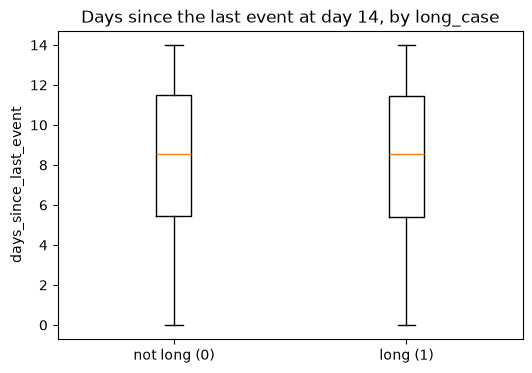

In [8]:
plt.figure(figsize=(6, 4))
plt.boxplot([features.loc[features["long_case"] == 0, "days_since_last_event"],
             features.loc[features["long_case"] == 1, "days_since_last_event"]])
plt.xticks([1, 2], ["not long (0)", "long (1)"])
plt.title("Days since the last event at day 14, by long_case")
plt.ylabel("days_since_last_event")
plt.show()

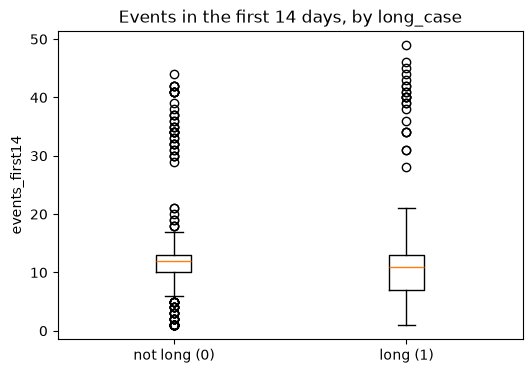

In [9]:
plt.figure(figsize=(6, 4))
plt.boxplot([features.loc[features["long_case"] == 0, "events_first14"],
             features.loc[features["long_case"] == 1, "events_first14"]])
plt.xticks([1, 2], ["not long (0)", "long (1)"])
plt.title("Events in the first 14 days, by long_case")
plt.ylabel("events_first14")
plt.show()

## 9. Define X and y

In [10]:
X = features[feature_columns]
y = features["long_case"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (917, 7)
y shape: (917,)


## 10. Train/Test Split

80% of the cases are used for training and 20% for testing. `stratify=y` keeps approximately the same class balance in
both sets.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training cases:", len(X_train))
print("Test cases:", len(X_test))

Training cases: 733
Test cases: 184


## 11. Simple Logistic Regression

No tuning. I also check that the model finished training (converged) within `max_iter`.

In [12]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

print("Iterations used:", model.n_iter_[0], "of", model.max_iter)

Iterations used: 36 of 1000


## 12. Evaluate

The positive class is **1 = long case**.

In [13]:
y_pred = model.predict(X_test)

print(f"Accuracy:  {accuracy_score(y_test, y_pred):.2f}")
print(f"Precision: {precision_score(y_test, y_pred):.2f}")
print(f"Recall:    {recall_score(y_test, y_pred):.2f}")
print(f"F1:        {f1_score(y_test, y_pred):.2f}")

Accuracy:  0.49
Precision: 0.50
Recall:    0.63
F1:        0.56


In [14]:
pd.DataFrame(
    confusion_matrix(y_test, y_pred),
    index=["actual 0 (not long)", "actual 1 (long)"],
    columns=["predicted 0", "predicted 1"],
)

,predicted 0,predicted 1
actual 0 (not long),30,59
actual 1 (long),35,60


## 13. Majority Baseline

Always predict the most common class in the training set. Accuracy alone is not enough: **recall** tells us how many of the
actual long cases the model successfully identifies. For an early-warning system, missing too many long cases would be a problem.

In [15]:
majority_class = y_train.mode()[0]
baseline_accuracy = (y_test == majority_class).mean()

print("Majority class in training set:", majority_class)
print(f"Majority baseline accuracy: {baseline_accuracy:.2f}")
print(f"Logistic Regression accuracy: {accuracy_score(y_test, y_pred):.2f}")

Majority class in training set: 1
Majority baseline accuracy: 0.52
Logistic Regression accuracy: 0.49


The majority class here is "long", so the baseline predicts **every** case as long. To compare recall and F1 fairly, I also
calculate them for this baseline:

In [16]:
baseline_pred = [majority_class] * len(y_test)

print(f"Baseline precision: {precision_score(y_test, baseline_pred):.2f}")
print(f"Baseline recall:    {recall_score(y_test, baseline_pred):.2f}")
print(f"Baseline F1:        {f1_score(y_test, baseline_pred):.2f}")
print("Cases the model predicted as long:", (y_pred == 1).sum(), "of", len(y_pred))

Baseline precision: 0.52
Baseline recall:    1.00
Baseline F1:        0.68
Cases the model predicted as long: 119 of 184


## 14. Compare with the First-5-Event Model

The first-5-event results come from notebook 06. The two experiments use slightly different groups of cases and different
test sets, so this comparison is a rough guide, not an exact head-to-head test.

In [17]:
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1"],
    "First 5 events": [0.55, 0.60, 0.28, 0.38],
    "Day 14 snapshot": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
    ],
})
comparison.round(2)

,Metric,First 5 events,Day 14 snapshot
0,Accuracy,0.55,0.49
1,Precision,0.60,0.50
2,Recall,0.28,0.63
3,F1,0.38,0.56


## 15. Interpretation

1. **Is the day-14 signal stronger than the first-five-event signal?** **No.** Recall (0.63 vs 0.28) and F1 (0.56 vs 0.38)
   look better, but accuracy (0.49 vs 0.55) and precision (0.50 vs 0.60) are worse. The higher recall mainly comes from the
   model predicting "long" much more often (119 of 184 test cases), not from recognising long cases better.
2. **Does Logistic Regression clearly beat the majority baseline?** **No.** Its accuracy (0.49) is slightly *below* the
   majority baseline (0.52). The baseline predicts every case as long and gets recall 1.00 and F1 0.68, both higher than the
   model. A precision of 0.50 is about the same as the share of long cases in the test set, so the model's "long" predictions
   are not more reliable than random guessing.
3. **What is recall for long cases?** 0.63: the model finds 60 of the 95 long test cases, but it also wrongly flags 59 of the
   89 not-long cases.
4. **Which early features differ most?** Long cases have slightly **less activity** in the first 14 days: fewer events
   (mean 11.13 vs 12.76) and fewer events in days 8–14 (mean 2.53 vs 3.56). The medians are very close (11 vs 12 events),
   and the boxplot shows a lot of overlap.
5. **Does inactivity (`days_since_last_event`) appear useful?** **No.** It is almost identical in both classes (mean 7.93 vs
   7.95 days, median about 8.5 days in both), and the boxplots look the same.
6. **Is the result strong enough to justify tree-based classifiers?** **No.** With these seven features there is almost no
   signal to work with, so a more complex model is unlikely to fix the problem.
7. **Is this closer to a valid early-warning setup?** **Yes.** The setup itself is better: every case is judged at the same
   moment (day 14), only cases that are still active are included, and no future information is used. The *setup* is more
   realistic, but the *features* are not yet informative enough.

## 16. Next Step

The signal remains weak, so the next step is to **improve the feature engineering before adding model complexity**. For
example, instead of only counting events, check *which* activities have (or have not) happened by day 14.

## 17. Important Limitations

- This is still an **exploratory proof of concept**.
- The dataset is from **one Dutch municipality**; it is **not SPAR or Montenegro data**.
- The 14-day prediction point is an **experimental choice**. A later project should test other prediction horizons, such as
  7, 21 or 30 days.
- The comparison with notebook 06 uses slightly different case groups and test sets, and both test sets are small (about
  190 cases), so small differences in the metrics should not be over-interpreted.